In [1]:
!pip install -q ultralytics deep-sort-realtime easyocr python-dotenv albumentations
!find /kaggle/input -maxdepth 5 -name DETRAC_Upload

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.2 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 29.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 kB 5.3 MB/s eta 0:00:00
/kaggle/input/datasets/narendrakalam/detrac-subset/DETRAC_Upload


In [3]:
import glob, os, shutil, zipfile

hit = glob.glob("/kaggle/input/**/scripts/train_detector.py", recursive=True)
if not hit:
    zips = glob.glob("/kaggle/input/**/*driveguard*.zip", recursive=True)
    print("extracted code nahi mila; zips:", zips)
    for z in zips:
        zipfile.ZipFile(z).extractall("/kaggle/working/_unz")
    hit = glob.glob("/kaggle/working/_unz/**/scripts/train_detector.py", recursive=True)

assert hit, "train_detector.py kahin nahi mila - left panel me driveguard-ai-code expand karke dekh"
src = os.path.dirname(os.path.dirname(hit[0]))
shutil.copytree(src, "/kaggle/working/driveguard-ai", dirs_exist_ok=True)
print("copied from:", src)
print(os.popen('grep -c "frame-stride" /kaggle/working/driveguard-ai/scripts/train_detector.py').read())

copied from: /kaggle/input/datasets/narendrakalam/driveguard-ai-code/driveguard-ai
1



root: /kaggle/input/datasets/narendrakalam/detrac-subset/DETRAC_Upload
train images: 8380 | train labels: 8380 | val images: 5634
class id counts (first 300 files): {'0': 21, '1': 2033, '2': 185, '3': 193}


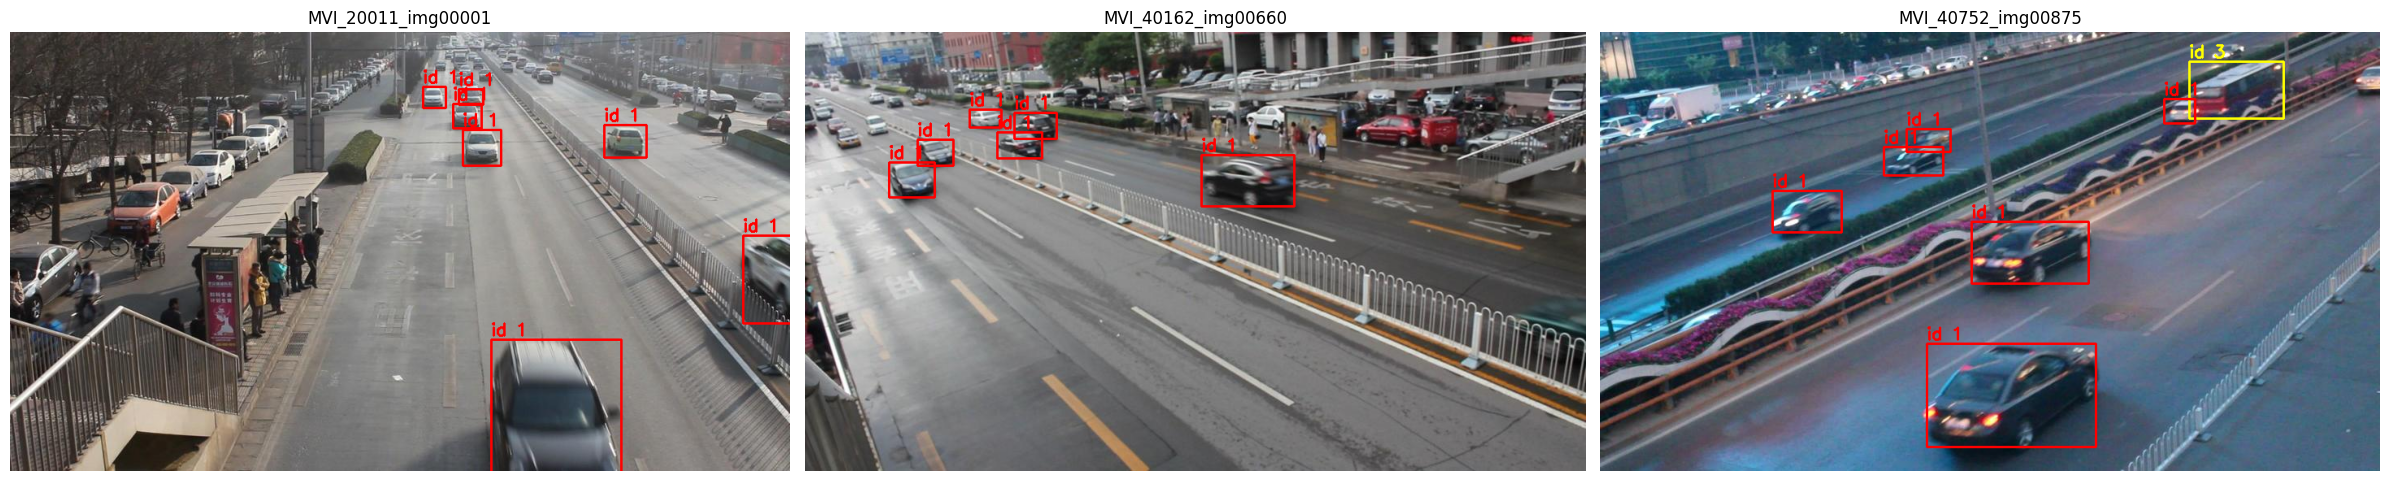

In [4]:
import glob, os, cv2
from collections import Counter
import matplotlib.pyplot as plt

root = glob.glob("/kaggle/input/**/DETRAC_Upload", recursive=True)[0]
print("root:", root)
lbls = sorted(glob.glob(f"{root}/labels/train/*.txt"))
n_img = len(glob.glob(f"{root}/images/train/*")); n_val = len(glob.glob(f"{root}/images/val/*"))
print(f"train images: {n_img} | train labels: {len(lbls)} | val images: {n_val}")

c = Counter()
for p in lbls[:300]:
    for line in open(p):
        if line.strip():
            c[line.split()[0]] += 1
print("class id counts (first 300 files):", dict(sorted(c.items())))

colors = {"0": (0, 255, 0), "1": (255, 0, 0), "2": (0, 0, 255), "3": (255, 255, 0)}
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
for ax, lp in zip(axes, lbls[:: max(1, len(lbls) // 3)][:3]):
    stem = os.path.splitext(os.path.basename(lp))[0]
    ip = glob.glob(f"{root}/images/train/{stem}.*")[0]
    img = cv2.cvtColor(cv2.imread(ip), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for line in open(lp):
        if not line.strip():
            continue
        cls, xc, yc, bw, bh = line.split()[:5]
        xc, yc, bw, bh = float(xc) * w, float(yc) * h, float(bw) * w, float(bh) * h
        x1, y1, x2, y2 = int(xc - bw / 2), int(yc - bh / 2), int(xc + bw / 2), int(yc + bh / 2)
        col = colors.get(cls, (255, 255, 255))
        cv2.rectangle(img, (x1, y1), (x2, y2), col, 2)
        cv2.putText(img, f"id {cls}", (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, col, 2)
    ax.imshow(img); ax.set_title(stem); ax.axis("off")
plt.tight_layout(); plt.show()

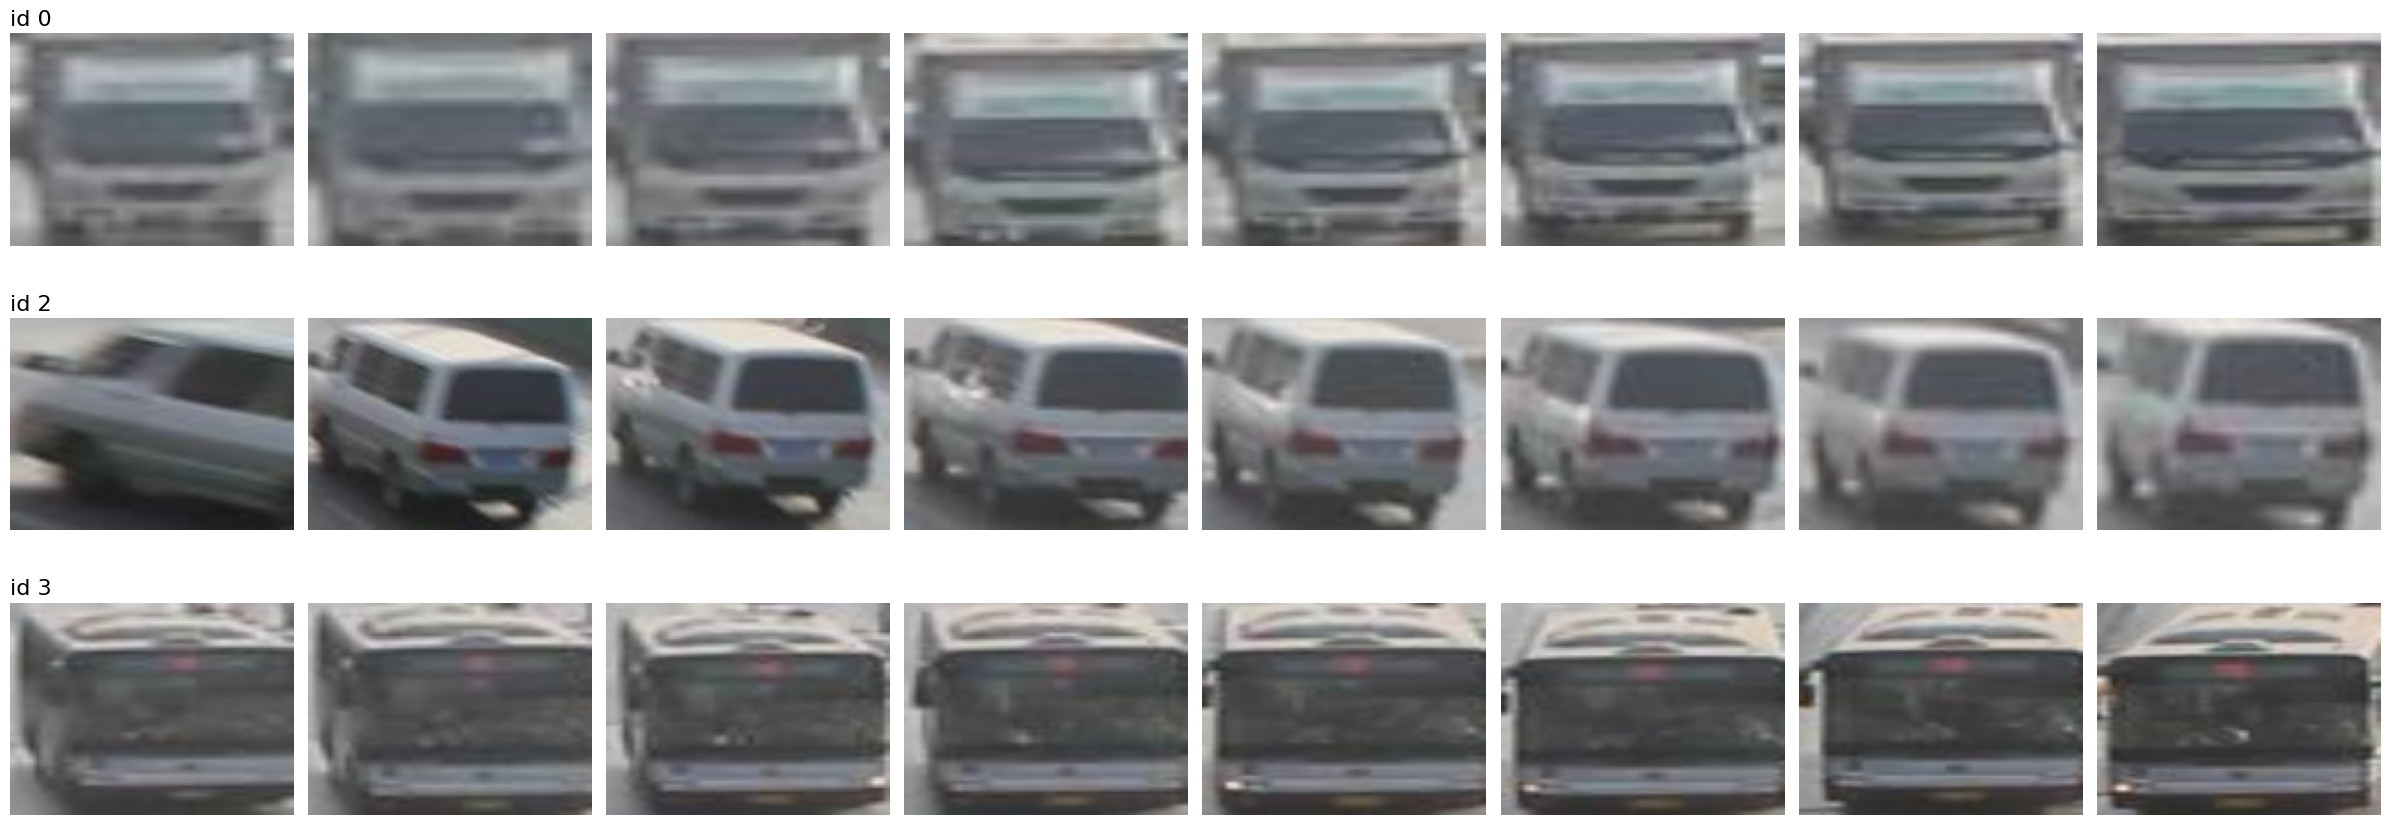

In [5]:
import glob, os, cv2
import matplotlib.pyplot as plt

root = glob.glob("/kaggle/input/**/DETRAC_Upload", recursive=True)[0]
lbls = sorted(glob.glob(f"{root}/labels/train/*.txt"))
crops = {"0": [], "2": [], "3": []}
for lp in lbls:
    if all(len(v) >= 8 for v in crops.values()):
        break
    stem = os.path.splitext(os.path.basename(lp))[0]
    rows = [l.split() for l in open(lp) if l.strip()]
    if not any(r[0] in crops and len(crops[r[0]]) < 8 for r in rows):
        continue
    img = cv2.cvtColor(cv2.imread(glob.glob(f"{root}/images/train/{stem}.*")[0]), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    for r in rows:
        k = r[0]
        if k in crops and len(crops[k]) < 8:
            xc, yc, bw, bh = [float(v) for v in r[1:5]]
            x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
            x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
            c = img[max(0, y1):y2, max(0, x1):x2]
            if c.size and c.shape[0] > 20 and c.shape[1] > 20:
                crops[k].append(cv2.resize(c, (160, 120)))

fig, axes = plt.subplots(3, 8, figsize=(24, 9))
for row, k in enumerate(["0", "2", "3"]):
    for col in range(8):
        ax = axes[row][col]; ax.axis("off")
        if col < len(crops[k]):
            ax.imshow(crops[k][col])
        if col == 0:
            ax.set_title(f"id {k}", loc="left", fontsize=16)
plt.tight_layout(); plt.show()

In [6]:
import os, json

# 1) config.py me Van class add
p = "/kaggle/working/driveguard-ai/src/config.py"
s = open(p).read()
assert '6: "Van"' not in s, "Van pehle se add hai, ye step skip kar"
old = '    5: "Bicycle",\n}'
assert old in s, "config.py ka format alag hai"
open(p, "w").write(s.replace(old, '    5: "Bicycle",\n    6: "Van",\n}'))
print(os.popen(f'grep -n -A9 "^VEHICLE_CLASSES" {p}').read())

# 2) class map
m = {
  "_comment": "ids confirmed visually: 0=truck, 1=car, 2=van, 3=bus",
  "*": {"0": "Truck", "1": "Car", "2": "Van", "3": "Bus"}
}
cm = "/kaggle/working/driveguard-ai/data/raw/ua_detrac_class_map.json"
json.dump(m, open(cm, "w"), indent=2)
print(open(cm).read())

111:VEHICLE_CLASSES: Dict[int, str] = {
112-    0: "Car",
113-    1: "Truck",
114-    2: "Bus",
115-    3: "Motorcycle",
116-    4: "Auto-rickshaw",
117-    5: "Bicycle",
118-    6: "Van",
119-}
120-

{
  "_comment": "ids confirmed visually: 0=truck, 1=car, 2=van, 3=bus",
  "*": {
    "0": "Truck",
    "1": "Car",
    "2": "Van",
    "3": "Bus"
  }
}


In [7]:
import glob
root = glob.glob("/kaggle/input/**/DETRAC_Upload", recursive=True)[0]
%cd /kaggle/working/driveguard-ai
!python scripts/train_detector.py \
  --yolo-dirs "{root}" \
  --class-map-file data/raw/ua_detrac_class_map.json \
  --frame-stride 1 --symlink \
  --epochs 30 --img-size 640 --batch 32 --device 0

/kaggle/working/driveguard-ai
{"time":"2026-10-15 03:17:09,279","level":"INFO","module":"__main__","message":"Merged /kaggle/input/datasets/narendrakalam/detrac-subset/DETRAC_Upload: 8380 train images, 5634 val images"}
{"time":"2026-10-15 03:17:09,280","level":"INFO","module":"__main__","message":"Merged dataset ready at /kaggle/working/driveguard-ai/data/processed/yolo_dataset: 8380 train / 5634 val images. data.yaml written to /kaggle/working/driveguard-ai/data/processed/yolo_dataset/data.yaml"}
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, bo

In [1]:
%cd /kaggle/working
!mkdir -p export
!cp driveguard-ai/models/yolov8_vehicle.pt driveguard-ai/models/model_card.json driveguard-ai/data/raw/ua_detrac_class_map.json export/
!cp driveguard-ai/models/runs/vehicle_detector/{results.png,results.csv,confusion_matrix_normalized.png,BoxPR_curve.png,val_batch0_pred.jpg} export/ 2>/dev/null || true
!zip -qr export.zip export && ls -la export export.zip

/kaggle/working
-rw-r--r-- 1 root root 49079140 Oct 15 07:54 export.zip

export:
total 52072
drwxr-xr-x 2 root root     4096 Oct 15 07:54 .
drwxr-xr-x 5 root root     4096 Oct 15 07:54 ..
-rw-r--r-- 1 root root   196761 Oct 15 07:54 BoxPR_curve.png
-rw-r--r-- 1 root root   197814 Oct 15 07:54 confusion_matrix_normalized.png
-rw-r--r-- 1 root root      700 Oct 15 07:54 model_card.json
-rw-r--r-- 1 root root     3934 Oct 15 07:54 results.csv
-rw-r--r-- 1 root root   346251 Oct 15 07:54 results.png
-rw-r--r-- 1 root root      151 Oct 15 07:54 ua_detrac_class_map.json
-rw-r--r-- 1 root root   532880 Oct 15 07:54 val_batch0_pred.jpg
-rw-r--r-- 1 root root 52011986 Oct 15 07:54 yolov8_vehicle.pt
